## ZADANIE 2

In [5]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/sprzedaz.csv", sep=";"
)
df.head()

,id,kanal,segment,wartosc
0,1,Internet,A,120
1,2,internet,B,250
2,3,Sklep,A,90
3,4,SKLEP,B,180
4,5,internet,A,310


## 2. struktura danych

In [6]:
print("Wiersze, kolumny:", df.shape)
print(df.dtypes)
print("Braki danych:")
print(df.isna().sum())
print("Duplikaty:", df.duplicated().sum())

Wiersze, kolumny: (12, 4)
id         int64
kanal        str
segment      str
wartosc    int64
dtype: object
Braki danych:
id         0
kanal      0
segment    0
wartosc    0
dtype: int64
Duplikaty: 0


## 3. statystyki

In [7]:
df["wartosc"].describe()

count     12.000000
mean     187.500000
std       95.262794
min       80.000000
25%      117.500000
50%      170.000000
75%      227.500000
max      400.000000
Name: wartosc, dtype: float64

## 4. sprawdzenie zapisu kanalow sprzedazy

In [8]:
df["kanal"].value_counts()

kanal
internet     3
Internet     2
Sklep        2
SKLEP        2
sklep        2
internet     1
Name: count, dtype: int64

## 5. ujednolicenie nazw kanalow

In [9]:
df["kanal"] = (
    df["kanal"].str.strip().str.lower()
)

df["kanal"].value_counts()

kanal
internet    6
sklep       6
Name: count, dtype: int64

## 6. obliczenia

In [10]:
liczba = df.groupby("kanal")["wartosc"].count()

sprzedaz = df.groupby("kanal")["wartosc"].sum()

print("\nLiczba zamówień w kanałach:")
print(liczba)
print("\nSuma wartości w kanałach:")
print(sprzedaz)
print("\nŚrednia wartość zamówienia:", df["wartosc"].mean())
print("\nMediana wartości zamówienia:", df["wartosc"].median())


Liczba zamówień w kanałach:
kanal
internet    6
sklep       6
Name: wartosc, dtype: int64

Suma wartości w kanałach:
kanal
internet    1490
sklep        760
Name: wartosc, dtype: int64

Średnia wartość zamówienia: 187.5

Mediana wartości zamówienia: 170.0


## 7. wykres slupkowy sumy sprzedazy wedlug kanalu

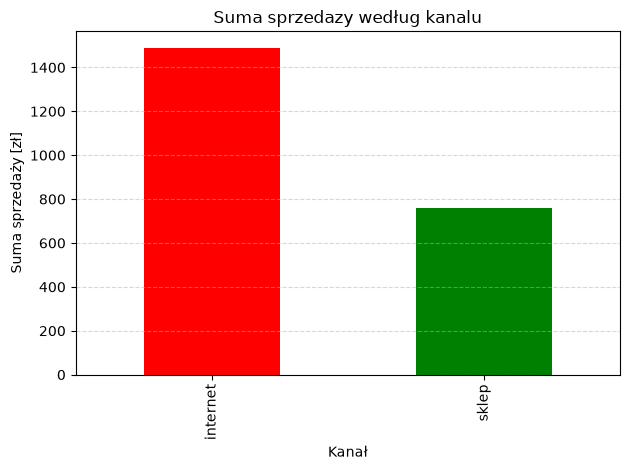

In [11]:
sprzedaz = df.groupby("kanal")[
    "wartosc"
].sum()

ax = sprzedaz.plot.bar(color=["red", "green"])
ax.set_title("Suma sprzedazy według kanalu")
ax.set_xlabel("Kanał")
ax.set_ylabel("Suma sprzedaży [zł]")
ax.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()                

# 8. wnioski

##1. Internet dominuje wartościowo. Kanał internetowy wygenerował 1490 zł z 2250 zł (ok. 66% całkowitej sprzedaży), a sklep 760 zł (ok. 34%).

##2. Zamówienia internetowe są większe. Oba kanały mają po 6 zamówień, ale średnia wartość zamówienia w internecie to ok. 248 zł, a w sklepie ok. 127 zł.